# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [4]:
STUDENT_NAME = 'Смачило Іванна Ростиславівна'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 11      # номер у списку групи

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 11, файл lr6_варіант_11.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [5]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [6]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [7]:
# ----- ВАШІ ВІДПОВІДІ -----

TYPE_OF_TASK = 'класифікація'      # 'класифікація' / 'регресія' / 'кластеризація' / 'зменшення розмірності'
# чому: ціль «відтік» має два значення(пішов / лишився) і потрібна оцінка ризику для кожного клієнта

METRIC = 'AUC'            # 'точність' / 'AUC' / 'F1' / 'повнота' / 'MAE'
# чому саме ця, а не точність: відтік становить ~25 %, тож «ніхто не піде» дає точність ~75 % при нульовій
# користі; AUC оцінює якість ранжування клієнтів за ризиком і не залежить від порогу, а відділу утримання
# потрібне саме впорядкування(кому телефонувати першим)

CV_SCHEME = 'стратифікована 5-кратна крос-валідація, 4 повтори'         # напр. 'стратифікована 5-кратна, 4 повтори'
# чому саме така: стратифікація зберігає частку відтоку в кожній згортці; 20 навчань дають не лише середнє,
# а й розкид, який потрібен для порівняння моделей; груп і часової осі в задачі немає(один рядок = один клієнт)

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')
print('точність тривіальної моделі «ніхто не піде»: %.3f' % (1 - pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')['відтік'].mean()))

рішення зафіксовані
точність тривіальної моделі «ніхто не піде»: 0.753


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [9]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.247

типи стовпців: {'str': 14, 'float64': 6, 'int64': 6}


In [10]:
# ----- ВАШ КОД: таблиця «стовпець | тип | унікальних | % пропусків | приклад» -----
# Відсортуйте за часткою пропусків спадно і покажіть усі стовпці.
info = pd.DataFrame({
    'тип':          raw.dtypes.astype(str),
    'унікальних':   raw.nunique(),
    '% пропусків':  (raw.isna().mean() * 100).round(1),
    'приклад':      [raw[c].dropna().iloc[0] if raw[c].notna().any() else None for c in raw.columns],
}).sort_values('% пропусків', ascending=False)
info.index.name = 'стовпець'
display(info)

,тип,унікальних,% пропусків,приклад
стовпець,,,,
дата_розірвання,str,241,75.3,2025-01-23
код_причини_закриття,str,5,75.3,ІНШ-09
середній_час_відповіді_хв,float64,260,34.0,8.8
трафік_ГБ,str,961,5.0,131.2
щомісячний_платіж,str,1137,4.0,268.95
аварій_на_ділянці_за_квартал,float64,6,3.0,0.0
id_клієнта,str,1200,0.0,K110000
кількість_дзвінків_утримання,int64,6,0.0,0
дата_підключення,str,593,0.0,2024-05-14


### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [11]:
# ----- ВАШ КОД: знайдіть і покажіть по кілька прикладів кожної проблеми -----
looks_numeric = lambda t: bool(re.match(r'^\s*[-+]?\d', str(t)))
for c in raw.columns:
    s = raw[c].dropna()
    if len(s) == 0 or pd.api.types.is_numeric_dtype(s):
        continue
    txt = s.astype(str)
    if txt.map(looks_numeric).mean() < 0.8:
        continue
    is_date = txt.str.match(r'^\d{4}-\d{2}-\d{2}')
    if is_date.mean() > 0.5:
        continue
    pure = txt.str.fullmatch(r'\s*[-+]?\d+(?:[.,]\d+)?\s*')
    text_part = ~pure & ~is_date
    if text_part.any():
        print('ТЕКСТ У ЧИСЛОВІЙ  :', c, '| %d значень, напр.' % text_part.sum(), txt[text_part].head(4).tolist())
    if is_date.any():
        print('EXCEL-ДАТА        :', c, '| %d значень, напр.' % is_date.sum(), txt[is_date].head(3).tolist())

print()
c = 'середній_час_відповіді_хв'
miss = raw[c].isna()
print('пропусків у %s: %.1f %%' % (c, miss.mean() * 100))
print('кількість звернень у підтримку там, де пропуск    :', sorted(raw.loc[miss, 'кількість_звернень_у_підтримку'].unique()))
print('кількість звернень у підтримку там, де значення є :', sorted(raw.loc[~miss, 'кількість_звернень_у_підтримку'].unique()))

ТЕКСТ У ЧИСЛОВІЙ  : щомісячний_платіж | 26 значень, напр. ['317.98 грн', '306.77 грн', '349.32 грн', '368.29 грн']
EXCEL-ДАТА        : трафік_ГБ | 3 значень, напр. ['1900-01-10 00:00:00', '1900-01-18 00:00:00', '1900-01-02 00:00:00']

пропусків у середній_час_відповіді_хв: 34.0 %
кількість звернень у підтримку там, де пропуск    : [np.int64(0)]
кількість звернень у підтримку там, де значення є : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


In [12]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'    # назва стовпця
PROBLEM_EXCEL_DATE     = 'трафік_ГБ'    # назва стовпця
PROBLEM_MNAR           = 'середній_час_відповіді_хв'    # назва стовпця
MNAR_MEANING           = ('пропуск означає, що клієнт жодного разу не звертався у підтримку(звернень = 0): '
                          'час відповіді просто не існує, а не «загубився»')    # що означає сам факт пропуску, одним реченням

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')

проблеми названо


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [15]:
NUM_RE  = re.compile(r'(?<!\w)[-+]?\d+(?:[.,]\d+)?')
DATE_RE = re.compile(r'^\s*\d{4}-\d{2}-\d{2}')

def to_number(s):
    """Витягує число з колонки, де перемішані числа, текст і дати."""
    def one(v):
        if v is None:
            return np.nan                                              # 1) None
        if isinstance(v, (datetime.datetime, datetime.date, pd.Timestamp)):
            return np.nan                                              # 2) дата -> брак, а не дані
        if isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, bool):
            return float(v)                                            # 3) число (NaN лишається NaN)
        t = str(v).strip()
        if DATE_RE.match(t):          # після read_csv Excel-дата приходить РЯДКОМ '1900-01-10 00:00:00'
            return np.nan
        m = NUM_RE.search(t)                                           # 4) перше число в тексті
        return float(m.group().replace(',', '.')) if m else np.nan
    return s.map(one)


# самоперевірка
_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
assert np.isnan(to_number(pd.Series(['1900-01-10 00:00:00']))[0]), 'рядок-дата теж має стати NaN'
print('to_number працює')

to_number працює


In [16]:
DROP_ALWAYS = ['id_клієнта']   # ідентифікатор: нічого не пояснює, лише запам'ятовується

def build_X(d, drop):
    """Сира таблиця -> матриця ознак. Категорії лишаємо типом category."""
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
        s = d[c]
        if c.startswith('дата_'):
            X[c] = (pd.to_datetime(s, errors='coerce') - pd.Timestamp('2000-01-01')).dt.days.astype(float)
            log.append({'стовпець': c, 'рішення': 'число (день)', 'чому': 'дата не годиться моделі, а номер дня — так'})
        elif pd.api.types.is_numeric_dtype(s):
            X[c] = s.astype(float)
            log.append({'стовпець': c, 'рішення': 'число', 'чому': 'вже числовий'})
        else:
            nn = s.dropna().astype(str)
            numlike = nn.map(lambda t: bool(re.match(r'^\s*[-+]?\d', t))).mean() if len(nn) else 0
            if numlike > 0.8 and to_number(nn).notna().mean() > 0.8:
                X[c] = to_number(s)
                log.append({'стовпець': c, 'рішення': 'число (to_number)', 'чому': '>80 %% значень — числа: %d нерозбірливих -> NaN'
                            % int(to_number(s).isna().sum() - s.isna().sum())})
            else:
                t = s.astype('object').where(s.notna(), None)
                t = t.map(lambda v: None if v is None else str(v).strip().lower())
                if c == 'стать':
                    t = t.map(lambda v: None if v is None else v[0])
                X[c] = t.astype('category')
                log.append({'стовпець': c, 'рішення': 'категорія', 'чому': 'регістр і пробіли уніфіковано, %d рівнів' % X[c].nunique()})
    return X, pd.DataFrame(log)


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

матриця ознак: (1200, 24)
категоріальних: 9


,стовпець,рішення,чому
0,вік,число,вже числовий
1,стать,категорія,"регістр і пробіли уніфіковано, 2 рівнів"
2,місто,категорія,"регістр і пробіли уніфіковано, 6 рівнів"
3,філія,категорія,"регістр і пробіли уніфіковано, 6 рівнів"
4,тариф,категорія,"регістр і пробіли уніфіковано, 4 рівнів"
5,тип_підключення,категорія,"регістр і пробіли уніфіковано, 3 рівнів"
6,спосіб_оплати,категорія,"регістр і пробіли уніфіковано, 3 рівнів"
7,автоплатіж,категорія,"регістр і пробіли уніфіковано, 2 рівнів"
8,кількість_послуг,число,вже числовий
9,місяців_обслуговування,число,вже числовий


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [17]:
def make_pipe(X, clf):
    cat = [c for c in X.columns if isinstance(X[c].dtype, pd.CategoricalDtype) or X[c].dtype == object]
    num = [c for c in X.columns if c not in cat]
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat),
    ])
    return Pipeline([('prep', prep), ('clf', clf)])


def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

# самоперевірка: конвеєр має бути єдиним оцінювачем і переживати крос-валідацію
_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())

конвеєр зібрано, пробний прогін AUC 0.988


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [18]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 0.986 ± 0.008
час      : 0.3 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [20]:
FIRST_REACTION = ('AUC %.3f — майже ідеальне розрізнення відтікачів, а на реальних даних такого не буває: '
                  'найімовірніше спрацювала причина «витік»(в таблиці є стовпці, записані вже після розірвання), '
                  'а не «задача виявилась легкою».' % auc_naive.mean())
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)

AUC 0.986 — майже ідеальне розрізнення відтікачів, а на реальних даних такого не буває: найімовірніше спрацювала причина «витік»(в таблиці є стовпці, записані вже після розірвання), а не «задача виявилась легкою».


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [21]:
def leak_scan(d, y, min_group=20):
    """Для кожного стовпця: наскільки добре його заповненість вгадує клас.

    Повертає таблицю зі стовпцями: ознака, заповнено, частка_відтоку_де_заповнено,
    частка_відтоку_де_пропуск, показник (0.5 = нічого, 1.0 = ідеальний поділ).
    """
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        filled = d[c].notna()
        n_f, n_m = int(filled.sum()), int((~filled).sum())
        ok = n_f >= min_group and n_m >= min_group
        score = np.nan
        if ok:
            a = roc_auc_score(y, filled.astype(int))
            score = max(a, 1 - a)
        rows.append({'ознака': c, 'заповнено': n_f,
                     'частка_відтоку_де_заповнено': y[filled].mean() if n_f else np.nan,
                     'частка_відтоку_де_пропуск': y[~filled].mean() if n_m else np.nan,
                     'показник': score})
    return pd.DataFrame(rows).sort_values('показник', ascending=False)


scan = leak_scan(raw, y)
display(scan.head(10))

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
22,код_причини_закриття,296,1.000000,0.000000,1.000000
23,дата_розірвання,296,1.000000,0.000000,1.000000
17,середній_час_відповіді_хв,792,0.276515,0.188725,0.553008
16,аварій_на_ділянці_за_квартал,1164,0.249141,0.166667,0.506458
12,щомісячний_платіж,1152,0.247396,0.229167,0.501884
14,трафік_ГБ,1140,0.246491,0.250000,0.500448
0,id_клієнта,1200,0.246667,NaN,NaN
1,вік,1200,0.246667,NaN,NaN
2,стать,1200,0.246667,NaN,NaN
3,місто,1200,0.246667,NaN,NaN


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [22]:
TARGET_LEAK = [
    'дата_розірвання',
    'код_причини_закриття',
]
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)

цільовий витік: ['дата_розірвання', 'код_причини_закриття']


In [23]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.923 ± 0.013


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [24]:
# ----- ВАШ КОД: перегляньте список стовпців, що лишились -----
print(list(X2.columns))
print()
chk = raw.groupby(TARGET)['кількість_дзвінків_утримання'].agg(['mean', 'median', 'max'])
chk.index = ['лишився (0)', 'пішов (1)']
display(chk.round(2))
print('заповненість кількість_дзвінків_утримання: %.0f %%' % (raw['кількість_дзвінків_утримання'].notna().mean() * 100))
print('AUC самої цієї ознаки як передбачувача відтоку: %.3f' % roc_auc_score(y, raw['кількість_дзвінків_утримання']))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'трафік_МБ', 'номер_договору_серія', 'індекс_лояльності_CRM', 'дата_підключення', 'кількість_дзвінків_утримання']



,mean,median,max
лишився (0),0.33,0.0,5
пішов (1),2.54,2.0,5


заповненість кількість_дзвінків_утримання: 100 %
AUC самої цієї ознаки як передбачувача відтоку: 0.869


In [25]:
HUMAN_LEAK = [
    'кількість_дзвінків_утримання',  # заповнює відділ утримання ПІСЛЯ того, як клієнт показав намір піти
]
HUMAN_LEAK_WHY = ('поле заповнене в усіх 1200 клієнтів (у тих, кому не телефонували, там 0), тому його заповненість '
                  'не залежить від класу, а детектор перевіряє лише факт наявності значення; витік у змісті '
                  'поля, а не в пропусках. У момент звернення договір ще чинний і утримання нікому не дзвонило')

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))

після вилучення оцінок людини: 21 ознак, AUC 0.840 ± 0.023


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

,частка відтоку,клієнтів
філія,,
Ф-01 Центр,0.422,199
Ф-02 Захід,0.398,186
Ф-03 Схід,0.214,182
Ф-04 Південь,0.163,208
Ф-05 Північ,0.135,222
Ф-06 Приміська,0.172,203


,частка відтоку,клієнтів
дата_підключення,,
2023Q1,0.194,134
2023Q2,0.196,158
2023Q3,0.250,160
2023Q4,0.324,148
2024Q1,0.242,153
2024Q2,0.183,164
2024Q3,0.319,144
2024Q4,0.273,139


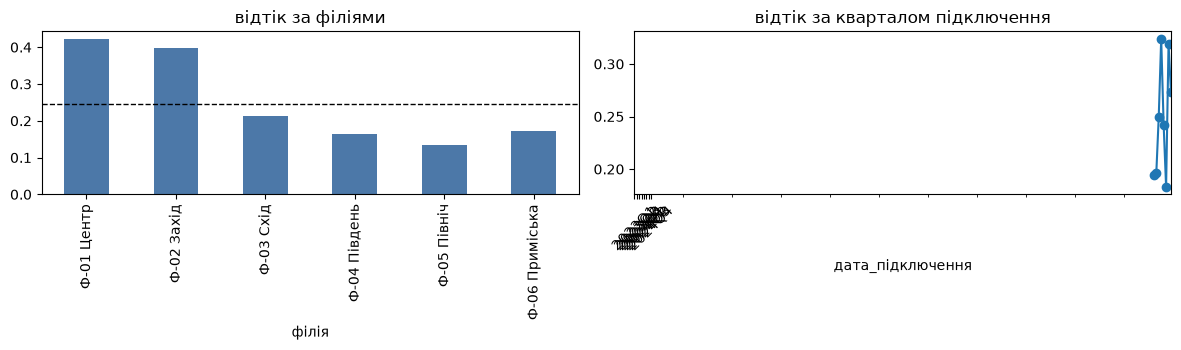

In [26]:
# ----- ВАШ КОД -----
# 1) частка відтоку за кожною філією (і скільки клієнтів у кожній);
# 2) частка відтоку по кварталах дати підключення — таблицею або графіком.
# Шукайте СХОДИНКУ, а не плавну зміну.
by_branch = raw.groupby('філія')[TARGET].agg(['mean', 'size']).round(3)
by_branch.columns = ['частка відтоку', 'клієнтів']
display(by_branch)

quarter = pd.to_datetime(raw['дата_підключення'], errors='coerce').dt.to_period('Q')
by_q = raw.groupby(quarter)[TARGET].agg(['mean', 'size']).round(3)
by_q.columns = ['частка відтоку', 'клієнтів']
display(by_q)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
by_branch['частка відтоку'].plot.bar(ax=ax[0], color='#4C78A8'); ax[0].set_title('відтік за філіями')
ax[0].axhline(raw[TARGET].mean(), color='k', ls='--', lw=1)
by_q['частка відтоку'].plot(ax=ax[1], marker='o'); ax[1].set_title('відтік за кварталом підключення')
ax[1].set_xticks(range(len(by_q))); ax[1].set_xticklabels([str(i) for i in by_q.index], rotation=45)
plt.tight_layout(); plt.show()

### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [27]:
SUSPECT = 'філія'        # 'філія' або 'дата_підключення' — що саме ви підозрюєте
assert SUSPECT in ('філія', 'дата_підключення')

rate = raw.groupby('філія')[TARGET].mean()
hot_branches = rate[rate > raw[TARGET].mean() + 0.10].index.tolist()
print('філії з різко іншою часткою відтоку:', hot_branches)
source = raw['філія'].isin(hot_branches).astype(int)

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))

філії з різко іншою часткою відтоку: ['Ф-01 Центр', 'Ф-02 Захід']
ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.676
ті самі ознаки передбачають ВІДТІК  : AUC 0.805 ± 0.029


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [28]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,0.986
2. мінус цільовий витік,22,0.923
3. мінус оцінки людини,21,0.840
4. мінус артефакт збору,20,0.805


чесне число: 0.805 ± 0.029


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [29]:
DECISION_ARTEFACT = 'викинути'
DECISION_WHY = ('сходинка між філіями різка (%s: %.0f–%.0f %% проти %.0f–%.0f %% в решти), а решта ознак вгадує джерело з AUC %.3f > 0,5, '
                'тож у даних закодоване правило обліку; модель має працювати в будь-якій філії, а з цим стовпцем вона частково '
                'вгадує філію (AUC %.3f -> %.3f після вилучення); якщо філія несе і справжній сигнал, '
                'його варто перевіряти окремо, а не вшивати в модель'
                % (' і '.join(hot_branches), rate[hot_branches].min() * 100, rate[hot_branches].max() * 100,
                   rate.drop(hot_branches).min() * 100, rate.drop(hot_branches).max() * 100,
                   auc_src.mean(), auc3.mean(), auc4.mean()))
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)

викинути — сходинка між філіями різка (Ф-01 Центр і Ф-02 Захід: 40–42 % проти 14–21 % в решти), а решта ознак вгадує джерело з AUC 0.676 > 0,5, тож у даних закодоване правило обліку; модель має працювати в будь-якій філії, а з цим стовпцем вона частково вгадує філію (AUC 0.840 -> 0.805 після вилучення); якщо філія несе і справжній сигнал, його варто перевіряти окремо, а не вшивати в модель


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [30]:
from sklearn.tree import DecisionTreeClassifier
MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(max_depth=5, random_state=SEED),
    'випадковий ліс':       RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
    'гістограмний бустинг': HistGradientBoostingClassifier(random_state=SEED),
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round((time.time() - t0) * 5, 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.805,0.029,1.3
одне дерево,0.710,0.043,1.0
випадковий ліс,0.822,0.032,12.6
гістограмний бустинг,0.822,0.032,34.1


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [31]:
def paired(a, b):
    """Повертає (середня різниця, півширина 95% інтервалу)."""
    d = np.asarray(b) - np.asarray(a)
    return d.mean(), 1.96 * d.std(ddof=1) / np.sqrt(len(d))


base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
gain_model = {}
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    gain_model[name] = (m, h)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

випадковий ліс         проти логістичної: +0.0175 ± 0.0121   значуще
гістограмний бустинг   проти логістичної: +0.0167 ± 0.0131   значуще


In [32]:
CHOSEN_MODEL = 'випадковий ліс'
_m, _h = gain_model['випадковий ліс']
_mh, _hh = gain_model['гістограмний бустинг']
CHOSEN_WHY = ('ліс дає AUC %.3f проти %.3f у логістичної (приріст %+.3f ± %.3f, значущий), бустинг практично не '
              'відрізняється від лісу (%+.3f ± %.3f проти логістичної), тож складніша модель нічого не додає; ліс обрано '
              'за точністю, а також тому, що дерева бачать нелінійності й взаємодії та працюють з TreeExplainer у частині 2; '
              'ціна — час (%.0f с проти %.0f с на 100 навчань), зате пояснення доступні'
              % (cmp_models.loc['випадковий ліс', 'AUC'], cmp_models.loc['логістична регресія', 'AUC'], _m, _h, _mh, _hh,
                 cmp_models.loc['випадковий ліс', 'с на 100 навчань'], cmp_models.loc['логістична регресія', 'с на 100 навчань']))
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)

обрано: випадковий ліс — ліс дає AUC 0.822 проти 0.805 у логістичної (приріст +0.018 ± 0.012, значущий), бустинг практично не відрізняється від лісу (+0.017 ± 0.013 проти логістичної), тож складніша модель нічого не додає; ліс обрано за точністю, а також тому, що дерева бачать нелінійності й взаємодії та працюють з TreeExplainer у частині 2; ціна — час (13 с проти 1 с на 100 навчань), зате пояснення доступні


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [33]:
def add_features(X):
    """Додає сконструйовані ознаки. Приймає і повертає матрицю ознак."""
    F = X.copy()
    # Гіпотеза 1: перші два роки — період ризику (кінець річного/дворічного договору, закінчення акційних умов)
    F['новий_клієнт'] = (F['місяців_обслуговування'] <= 24).astype(float)
    # Гіпотеза 2: звернення треба рахувати відносно стажу — 3 звернення за пів року і за 5 років — різні сигнали
    F['звернень_на_місяць'] = F['кількість_звернень_у_підтримку'] / (F['місяців_обслуговування'] + 1)
    # Гіпотеза 3: ціна однієї послуги — хто платить багато за одну послугу, відчуває переплату й шукає альтернативу
    F['платіж_на_послугу'] = F['щомісячний_платіж'] / F['кількість_послуг']
    # Гіпотеза 4: повільна підтримка (понад 8 хв) дратує; NaN (не звертався) -> 0, тут це «не було проблеми»
    F['повільна_підтримка'] = (F['середній_час_відповіді_хв'].fillna(0) > 8).astype(float)
    return F


X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))

було 20 ознак, стало 24


In [34]:
t0 = time.time()
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
t_feat = (time.time() - t0) * 5
m, h = paired(base, auc5)
gain_feat = (m, h)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

for c in [c for c in X5.columns if c not in X4.columns]:
    Xc = X4.copy(); Xc[c] = X5[c]
    mm, hh = paired(base, cross_val_score(make_pipe(Xc, logreg()), Xc, y, cv=cv, scoring='roc_auc'))
    print('   %-26s %+0.4f ± %.4f  %s' % (c, mm, hh, 'значуще' if abs(mm) > hh else 'у межах шуму'))

з новими ознаками: AUC 0.811 ± 0.027
приріст проти базового набору: +0.0055 ± 0.0015   значуще
   новий_клієнт               +0.0069 ± 0.0017  значуще
   звернень_на_місяць         -0.0011 ± 0.0013  у межах шуму
   платіж_на_послугу          -0.0005 ± 0.0006  у межах шуму
   повільна_підтримка         -0.0001 ± 0.0018  у межах шуму


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [35]:
_mf, _hf = gain_feat
_mr, _hr = gain_model['випадковий ліс']
FEATURES_VS_MODEL = ('нові ознаки на логістичній регресії: %+.4f ± %.4f (%s), %.1f с на 100 навчань; '
                     'складніша модель (ліс): %+.4f ± %.4f (%s), %.0f с на 100 навчань. '
                     'Більше дала складніша модель (приріст приблизно ×%.0f), але ціною обчислення, довшого приблизно ×%.0f; '
                     'нові ознаки майже безкоштовні, але з чотирьох гіпотез спрацювала лише одна (новий_клієнт).'
                     % (_mf, _hf, 'значуще' if abs(_mf) > _hf else 'у межах шуму', t_feat,
                        _mr, _hr, 'значуще' if abs(_mr) > _hr else 'у межах шуму',
                        cmp_models.loc['випадковий ліс', 'с на 100 навчань'],
                        abs(_mr / _mf) if _mf else float('nan'),
                        cmp_models.loc['випадковий ліс', 'с на 100 навчань'] / max(t_feat, 0.1)))
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

нові ознаки на логістичній регресії: +0.0055 ± 0.0015 (значуще), 1.4 с на 100 навчань; складніша модель (ліс): +0.0175 ± 0.0121 (значуще), 13 с на 100 навчань. Більше дала складніша модель (приріст приблизно ×3), але ціною обчислення, довшого приблизно ×9; нові ознаки майже безкоштовні, але з чотирьох гіпотез спрацювала лише одна (новий_клієнт).


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [36]:
FINAL_X = X5                      # з якою матрицею працюємо далі
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.807
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

,вбудована важливість
номер_договору_серія,0.108638
щомісячний_платіж,0.108231
вік,0.073719
швидкість_тарифу_Мбіт,0.067397
трафік_МБ,0.064107
трафік_ГБ,0.062381
місяців_обслуговування,0.055988
платіж_на_послугу,0.053946
звернень_на_місяць,0.047717
індекс_лояльності_CRM,0.045885


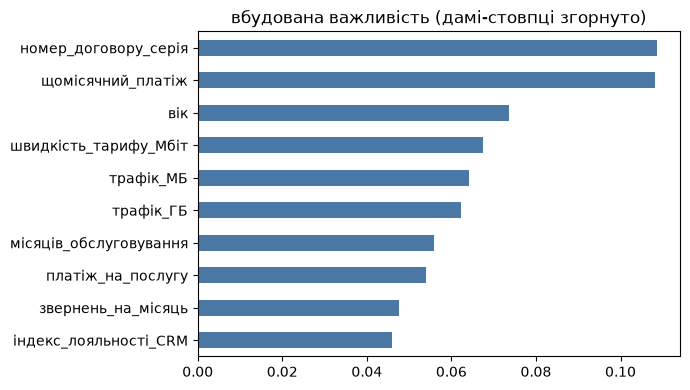

In [37]:
prep_ = model.named_steps['prep']
rf_ = model.named_steps['clf']
names_t = prep_.get_feature_names_out()

def origin(n):
    n = n.split('__', 1)[1]
    for c in sorted(FINAL_X.columns, key=len, reverse=True):
        if n == c or n.startswith(c + '_'):
            return c
    return n

gini_imp = (pd.Series(rf_.feature_importances_, index=[origin(n) for n in names_t])
            .groupby(level=0).sum().sort_values(ascending=False))
display(gini_imp.head(10).to_frame('вбудована важливість'))
gini_imp.head(10)[::-1].plot.barh(figsize=(7, 4), color='#4C78A8')
plt.title('вбудована важливість (дамі-стовпці згорнуто)'); plt.tight_layout(); plt.show()

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [38]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
вік,0.053147
щомісячний_платіж,0.022484
місяців_обслуговування,0.015370
звернень_на_місяць,0.012459
автоплатіж,0.010523
новий_клієнт,0.008997
трафік_МБ,0.008114
швидкість_тарифу_Мбіт,0.007204
трафік_ГБ,0.005952
кількість_звернень_у_підтримку,0.004239


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [39]:
# ----- ВАШ КОД: таблиця «ознака | вбудована | перестановочна», відсортована за вбудованою -----
cmp_imp = pd.DataFrame({'вбудована': gini_imp, 'перестановочна': perm_imp}).sort_values('вбудована', ascending=False).round(4)
display(cmp_imp.head(12))

,вбудована,перестановочна
номер_договору_серія,0.1086,-0.0034
щомісячний_платіж,0.1082,0.0225
вік,0.0737,0.0531
швидкість_тарифу_Мбіт,0.0674,0.0072
трафік_МБ,0.0641,0.0081
трафік_ГБ,0.0624,0.0060
місяців_обслуговування,0.0560,0.0154
платіж_на_послугу,0.0539,-0.0020
звернень_на_місяць,0.0477,0.0125
індекс_лояльності_CRM,0.0459,-0.0015


In [40]:
FAKE_IMPORTANT = 'номер_договору_серія'
FAKE_IMPORTANT_WHY = ('55 різних значень дають дереву безліч порогів, і воно майже завжди знаходить розбиття, що трохи зменшує '
                      'неоднорідність на навчальних даних, хоча зв\'язку з відтоком нема; вбудована важливість рахується на навчальних '
                      'даних, а перестановочна на перевірковій — і там вона %.4f (≈0)' % perm_imp['номер_договору_серія'])
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
assert gini_imp.index.get_loc(FAKE_IMPORTANT) < 5 and perm_imp[FAKE_IMPORTANT] < 0.005
print('хибно важлива ознака:', FAKE_IMPORTANT)
print('   вбудована %.4f (місце %d), перестановочна %.4f' % (gini_imp[FAKE_IMPORTANT],
      gini_imp.index.get_loc(FAKE_IMPORTANT) + 1, perm_imp[FAKE_IMPORTANT]))

хибно важлива ознака: номер_договору_серія
   вбудована 0.1086 (місце 1), перестановочна -0.0034


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [41]:
# ----- ВАШ КОД: кореляційна матриця числових ознак, знайдіть пару з |r| > 0.97 -----
numcols = [c for c in FINAL_X.columns if pd.api.types.is_numeric_dtype(FINAL_X[c])]
cm = FINAL_X[numcols].corr().abs()
pairs = cm.where(np.triu(np.ones(cm.shape, dtype=bool), 1)).stack().sort_values(ascending=False)
display(pairs.head(5).to_frame('|r|'))

,,|r|
трафік_ГБ,трафік_МБ,0.999750
місяців_обслуговування,новий_клієнт,0.771068
швидкість_тарифу_Мбіт,щомісячний_платіж,0.757894
кількість_послуг,платіж_на_послугу,0.678362
середній_час_відповіді_хв,повільна_підтримка,0.658365


In [42]:
DUP_PAIR = ['трафік_ГБ', 'трафік_МБ']        # той самий трафік у різних одиницях (1 ГБ = 1024 МБ)
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

Xtr_d, Xte_d = Xtr.drop(columns=[DUP_PAIR[1]]), Xte.drop(columns=[DUP_PAIR[1]])
model_d = make_pipe(Xtr_d, RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)).fit(Xtr_d, ytr)
perm_d = permutation_importance(model_d, Xte_d, yte, n_repeats=10, random_state=SEED, scoring='roc_auc')
perm_d = pd.Series(perm_d.importances_mean, index=Xte_d.columns)
print('без %s:' % DUP_PAIR[1])
print('   %-28s %+.4f' % (DUP_PAIR[0], perm_d[DUP_PAIR[0]]))
print('AUC на відкладеній частині: з парою %.3f, без дублера %.3f'
      % (auc_hold, roc_auc_score(yte, model_d.predict_proba(Xte_d)[:, 1])))

у повній моделі:
   трафік_ГБ                    +0.0060
   трафік_МБ                    +0.0081
без трафік_МБ:
   трафік_ГБ                    +0.0467
AUC на відкладеній частині: з парою 0.807, без дублера 0.806


In [43]:
DUP_EXPLANATION = ('у повній моделі перестановочна важливість трафіку розділилась між двома колонками (%+.4f і %+.4f): '
                   'перемішуючи одну, ми лишаємо моделі ту саму інформацію в другій; після вилучення %s вага %s стала %+.4f, '
                   'тобто разом трафік важливіший, ніж видно з кожної колонки окремо; метод не бреше — він чесно відповідає, '
                   'наскільки гірше стане БЕЗ цієї колонки, а вада лише в висновку «важливість мала, отже викинути»'
                   % (perm_imp[DUP_PAIR[0]], perm_imp[DUP_PAIR[1]], DUP_PAIR[1], DUP_PAIR[0], perm_d[DUP_PAIR[0]]))
assert DUP_EXPLANATION
print(DUP_EXPLANATION)

у повній моделі перестановочна важливість трафіку розділилась між двома колонками (+0.0060 і +0.0081): перемішуючи одну, ми лишаємо моделі ту саму інформацію в другій; після вилучення трафік_МБ вага трафік_ГБ стала +0.0467, тобто разом трафік важливіший, ніж видно з кожної колонки окремо; метод не бреше — він чесно відповідає, наскільки гірше стане БЕЗ цієї колонки, а вада лише в висновку «важливість мала, отже викинути»


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

три найважливіші числові ознаки за перестановочною важливістю: ['вік', 'щомісячний_платіж', 'місяців_обслуговування']
   увага: щомісячний_платіж має пропуски — PDP побудовано на 341 із 360 рядків


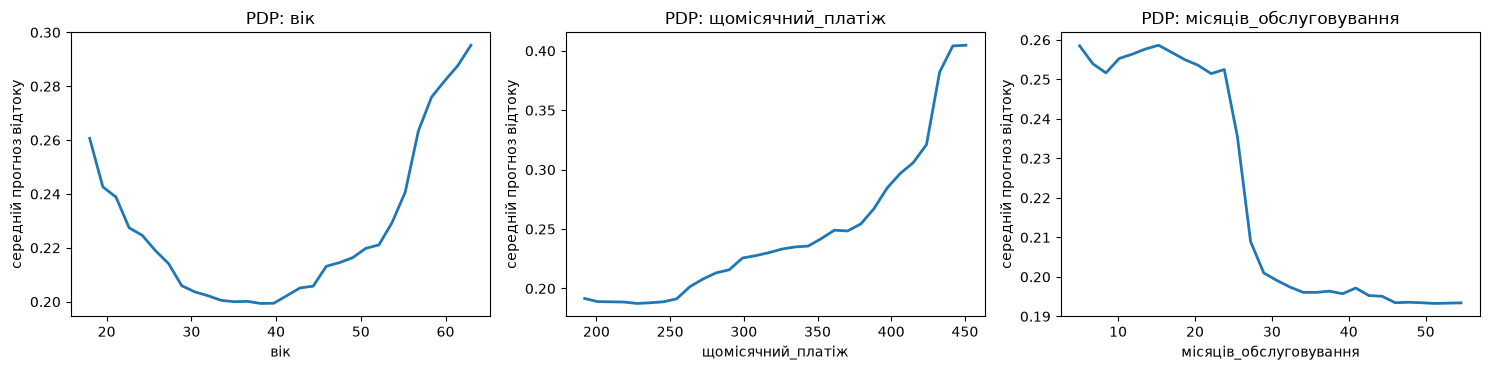

вік                      мінімум 0.199 при 38.17, максимум 0.295 при 63, на краях 0.261 і 0.295 -> НЕмонотонна
щомісячний_платіж        мінімум 0.187 при 227.7, максимум 0.405 при 450.7, на краях 0.192 і 0.405 -> приблизно монотонна
місяців_обслуговування   мінімум 0.193 при 51.17, максимум 0.259 при 15.26, на краях 0.258 і 0.193 -> приблизно монотонна


In [44]:
from sklearn.inspection import PartialDependenceDisplay

num_ranked = [c for c in perm_imp.index if pd.api.types.is_numeric_dtype(FINAL_X[c])]
top3 = num_ranked[:3]
print('три найважливіші числові ознаки за перестановочною важливістю:', top3)

fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, f in zip(axs, top3):
    sub = Xte[Xte[f].notna()]
    if len(sub) < len(Xte):
        print('   увага: %s має пропуски — PDP побудовано на %d із %d рядків' % (f, len(sub), len(Xte)))
    r = partial_dependence(model, sub, [f], kind='average', grid_resolution=30)
    ax.plot(r['grid_values'][0], r['average'][0], lw=2)
    ax.set_xlabel(f); ax.set_ylabel('середній прогноз відтоку'); ax.set_title('PDP: ' + f)
plt.tight_layout(); plt.show()

for f in top3:
    sub = Xte[Xte[f].notna()]
    r = partial_dependence(model, sub, [f], kind='average', grid_resolution=30)
    gx, ay = r['grid_values'][0], r['average'][0]
    mono = bool(np.all(np.diff(ay) >= -0.005) or np.all(np.diff(ay) <= 0.005))
    print('%-24s мінімум %.3f при %.4g, максимум %.3f при %.4g, на краях %.3f і %.3f -> %s'
          % (f, ay.min(), gx[ay.argmin()], ay.max(), gx[ay.argmax()], ay[0], ay[-1],
             'приблизно монотонна' if mono else 'НЕмонотонна'))

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

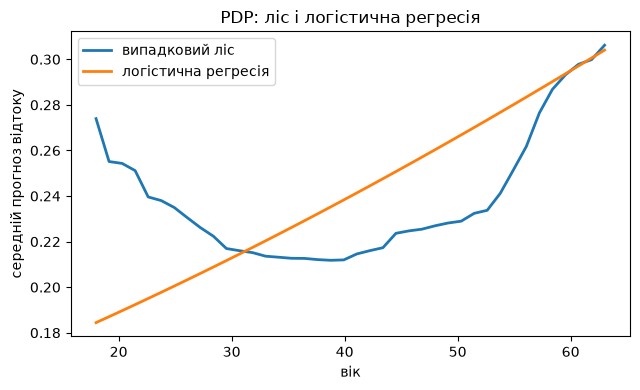

ліс: мінімум ризику при вік = 39 (прогноз 0.212); на краях 0.274 (молодші) і 0.306 (старші)
логістична регресія: монотонна = True


In [45]:
NONLINEAR_FEATURE = 'вік'
assert NONLINEAR_FEATURE in FINAL_X.columns

lrm = make_pipe(FINAL_X, logreg()).fit(Xtr, ytr)
fig, ax = plt.subplots(figsize=(6.5, 4))
curves = {}
for nm, mod in [('випадковий ліс', model), ('логістична регресія', lrm)]:
    r = partial_dependence(mod, FINAL_X, [NONLINEAR_FEATURE], kind='average', grid_resolution=40)
    g, a = r['grid_values'][0], r['average'][0]
    curves[nm] = (g, a)
    ax.plot(g, a, lw=2, label=nm)
ax.set_xlabel(NONLINEAR_FEATURE); ax.set_ylabel('середній прогноз відтоку'); ax.legend(); ax.set_title('PDP: ліс і логістична регресія')
plt.tight_layout(); plt.show()

g, a = curves['випадковий ліс']; i_min = int(np.argmin(a))
print('ліс: мінімум ризику при %s = %.0f (прогноз %.3f); на краях %.3f (молодші) і %.3f (старші)'
      % (NONLINEAR_FEATURE, g[i_min], a[i_min], a[0], a[-1]))
g2, a2 = curves['логістична регресія']
print('логістична регресія: монотонна =', bool(np.all(np.diff(a2) >= -1e-9) or np.all(np.diff(a2) <= 1e-9)))
assert 0 < i_min < len(a) - 1, 'мінімум має бути всередині діапазону'

In [46]:
NONLINEAR_MEANING = ('вік: ризик відтоку високий у наймолодших і найстарших клієнтів і мінімальний у середньому віці (близько %.0f років): '
                     'молоді легко змінюють провайдера, літні складніше користуються послугою — U-подібна залежність' % g[i_min])
NONLINEAR_FIX = 'квадрат відхилення віку від точки мінімуму ризику: (вік − %.0f)²' % g[i_min]
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)

вік: ризик відтоку високий у наймолодших і найстарших клієнтів і мінімальний у середньому віці (близько 39 років): молоді легко змінюють провайдера, літні складніше користуються послугою — U-подібна залежність
квадрат відхилення віку від точки мінімуму ризику: (вік − 39)²


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [47]:
# ----- ВАШ КОД -----
# 1) зчитайте з графіка значення, при якому ризик мінімальний;
# 2) додайте ознаку «квадрат відхилення від цього значення»;
# 3) парне порівняння логістичної регресії з нею і без неї.
age0 = float(g[i_min])
FX_q = FINAL_X.copy()
FX_q['вік_відхилення_кв'] = (FX_q['вік'] - age0) ** 2
a_without = cross_val_score(make_pipe(FINAL_X, logreg()), FINAL_X, y, cv=cv, scoring='roc_auc')
a_with    = cross_val_score(make_pipe(FX_q, logreg()), FX_q, y, cv=cv, scoring='roc_auc')
qg, qh = paired(a_without, a_with)
print('логістична без ознаки: %.3f; з ознакою: %.3f; приріст %+.4f ± %.4f (%s)'
      % (a_without.mean(), a_with.mean(), qg, qh, 'значуще' if abs(qg) > qh else 'у межах шуму'))

логістична без ознаки: 0.811; з ознакою: 0.848; приріст +0.0374 ± 0.0076 (значуще)


In [48]:
QUAD_GAIN = qg     # приріст AUC лінійної моделі від нової ознаки
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)

приріст від сконструйованої ознаки: +0.0374


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

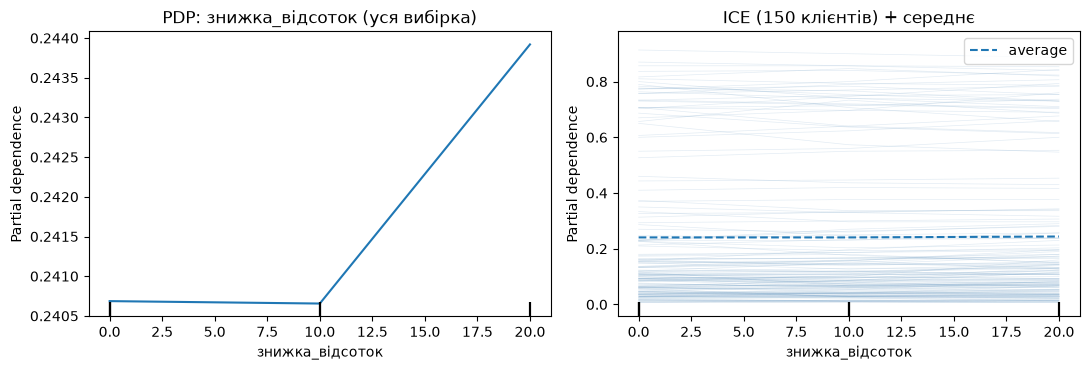

PDP по всій вибірці: {0: np.float64(0.241), 10: np.float64(0.241), 20: np.float64(0.244)} — розмах 0.003
ICE: у 50 % клієнтів знижка 20 % підвищує прогноз, у 44 % — знижує


In [49]:
# ----- ВАШ КОД: пункт 1 і 2, PDP та ICE для 'знижка_відсоток' -----
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'], kind='average', ax=axs[0])
axs[0].set_title('PDP: знижка_відсоток (уся вибірка)')
PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'], kind='both',
                                        subsample=150, random_state=SEED, ax=axs[1],
                                        ice_lines_kw={'alpha': 0.15, 'color': 'steelblue'})
axs[1].set_title('ICE (150 клієнтів) + середнє')
plt.tight_layout(); plt.show()

r = partial_dependence(model, FINAL_X, ['знижка_відсоток'], kind='average')
pdp_all = dict(zip(r['grid_values'][0], r['average'][0]))
print('PDP по всій вибірці:', {int(k): round(v, 3) for k, v in pdp_all.items()},
      '— розмах %.3f' % (max(pdp_all.values()) - min(pdp_all.values())))
ice = partial_dependence(model, FINAL_X, ['знижка_відсоток'], kind='individual')['individual'][0]
slope = ice[:, -1] - ice[:, 0]
print('ICE: у %.0f %% клієнтів знижка 20 %% підвищує прогноз, у %.0f %% — знижує' % ((slope > 0).mean() * 100, (slope < 0).mean() * 100))

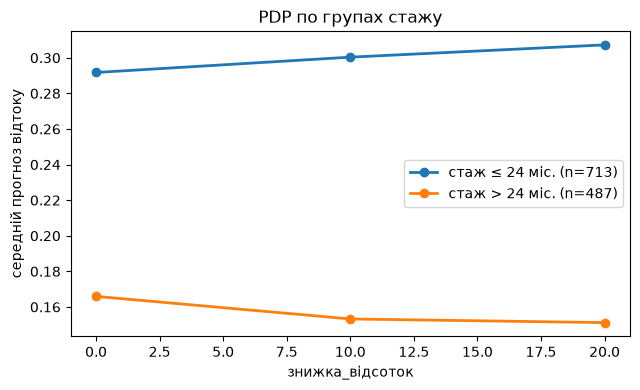

стаж ≤ 24 міс. {0: np.float64(0.292), 10: np.float64(0.3), 20: np.float64(0.307)}
стаж > 24 міс. {0: np.float64(0.166), 10: np.float64(0.153), 20: np.float64(0.151)}


In [50]:
# ----- ВАШ КОД: пункт 3, дві криві на одному рисунку -----
# підказка: partial_dependence(model, FINAL_X[mask], ['знижка_відсоток'], kind='average')
short = (FINAL_X['місяців_обслуговування'] <= 24).values
fig, ax = plt.subplots(figsize=(6.5, 4))
pdp_grp = {}
for nm, mask in [('стаж ≤ 24 міс.', short), ('стаж > 24 міс.', ~short)]:
    r = partial_dependence(model, FINAL_X[mask], ['знижка_відсоток'], kind='average')
    ax.plot(r['grid_values'][0], r['average'][0], marker='o', lw=2, label='%s (n=%d)' % (nm, mask.sum()))
    pdp_grp[nm] = dict(zip(r['grid_values'][0], r['average'][0]))
ax.set_xlabel('знижка_відсоток'); ax.set_ylabel('середній прогноз відтоку'); ax.legend()
ax.set_title('PDP по групах стажу'); plt.tight_layout(); plt.show()
for k, v in pdp_grp.items():
    print(k, {int(a): round(b, 3) for a, b in v.items()})

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [51]:
# ----- ВАШ КОД: зведена таблиця «знижка x група стажу» -> частка відтоку і розмір групи -----
grp = np.where(X4['місяців_обслуговування'] <= 24, 'стаж ≤ 24', 'стаж > 24')
emp_rate = pd.pivot_table(raw.assign(група=grp), values=TARGET, index='група', columns='знижка_відсоток', aggfunc='mean').round(3)
emp_n    = pd.pivot_table(raw.assign(група=grp), values=TARGET, index='група', columns='знижка_відсоток', aggfunc='size')
print('частка відтоку:'); display(emp_rate)
print('розмір групи:');   display(emp_n)

FX_i = FINAL_X.copy(); FX_i['знижка_х_новий'] = FX_i['знижка_відсоток'] * FX_i['новий_клієнт']
a_i = cross_val_score(make_pipe(FX_i, logreg()), FX_i, y, cv=cv, scoring='roc_auc')
ig, ih = paired(a_without, a_i)
print('логістична з ознакою «знижка × новий клієнт»: приріст %+.4f ± %.4f (%s)' % (ig, ih, 'значуще' if abs(ig) > ih else 'у межах шуму'))

частка відтоку:


знижка_відсоток,0,10,20
група,,,
стаж > 24,0.224,0.071,0.070
стаж ≤ 24,0.253,0.377,0.362


розмір групи:


знижка_відсоток,0,10,20
група,,,
стаж > 24,205,140,142
стаж ≤ 24,289,239,185


логістична з ознакою «знижка × новий клієнт»: приріст +0.0181 ± 0.0046 (значуще)


In [52]:
_s0, _s20 = emp_rate.loc['стаж ≤ 24', 0], emp_rate.loc['стаж ≤ 24', 20]
_l0, _l20 = emp_rate.loc['стаж > 24', 0], emp_rate.loc['стаж > 24', 20]
_ms, _ml = pdp_grp['стаж ≤ 24 міс.'], pdp_grp['стаж > 24 міс.']
INTERACTION_FOUND = ('PDP по всій вибірці майже плаский (розмах %.3f), але по групах ефект протилежний. '
                     'Сирі дані: стаж ≤ 24 міс. — відтік %.1f %% без знижки і %.1f %% зі знижкою 20 %% (зростає); '
                     'стаж > 24 міс. — %.1f %% і %.1f %% (спадає). PDP моделі відтворює напрямки (%+.3f і %+.3f при зміні знижки з 0 до 20 %%), '
                     'але слабше за сирі дані; ICE: у %.0f %% клієнтів крива йде вгору, у %.0f %% — вниз'
                     % (max(pdp_all.values()) - min(pdp_all.values()), _s0 * 100, _s20 * 100, _l0 * 100, _l20 * 100,
                        _ms[20] - _ms[0], _ml[20] - _ml[0], (slope > 0).mean() * 100, (slope < 0).mean() * 100))
BUSINESS_ACTION = ('пропонувати знижку лише клієнтам зі стажем понад 24 місяці, де вона пов’язана зі зниженням відтоку; '
                   'клієнтам зі стажем до 24 місяців вона не допомагає (відтік не знижується), їм потрібен інший захід; '
                   'оскільки це спостереження, а не експеримент, ефект варто перевірити невеликим A/B-тестом')
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)

PDP по всій вибірці майже плаский (розмах 0.003), але по групах ефект протилежний. Сирі дані: стаж ≤ 24 міс. — відтік 25.3 % без знижки і 36.2 % зі знижкою 20 % (зростає); стаж > 24 міс. — 22.4 % і 7.0 % (спадає). PDP моделі відтворює напрямки (+0.016 і -0.015 при зміні знижки з 0 до 20 %), але слабше за сирі дані; ICE: у 50 % клієнтів крива йде вгору, у 44 % — вниз
пропонувати знижку лише клієнтам зі стажем понад 24 місяці, де вона пов’язана зі зниженням відтоку; клієнтам зі стажем до 24 місяців вона не допомагає (відтік не знижується), їм потрібен інший захід; оскільки це спостереження, а не експеримент, ефект варто перевірити невеликим A/B-тестом


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [53]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])      # щоб рахувалось за секунди
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (300, 92)


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

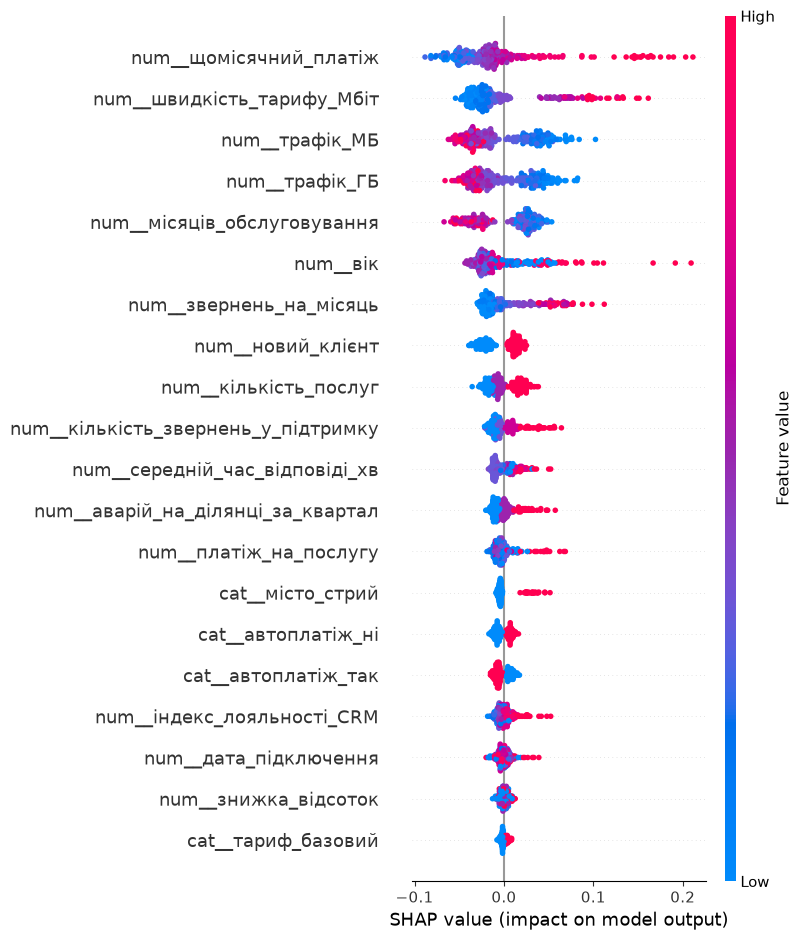

середній |внесок Шеплі| за ознаками (топ-5):


,mean|SHAP|
щомісячний_платіж,0.0389
швидкість_тарифу_Мбіт,0.0349
трафік_МБ,0.0341
номер_договору_серія,0.0335
трафік_ГБ,0.0304


In [54]:
# ----- ВАШ КОД: shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names) -----
shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names)
_shap_rank = pd.Series(np.abs(sv1).mean(0), index=[origin(n) for n in feat_names]).groupby(level=0).sum().sort_values(ascending=False)
print('середній |внесок Шеплі| за ознаками (топ-5):'); display(_shap_rank.head(5).round(4).to_frame('mean|SHAP|'))

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [55]:
_p = model.predict_proba(Xte)[:SAMPLE, 1]
idx = int(np.argmax(_p))
print('ризик клієнта: %.3f' % _p[idx])

contrib = pd.Series(sv1[idx], index=[origin(n) for n in feat_names]).groupby(level=0).sum()
top3_c = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(3)
base_value = float(np.ravel(expl.expected_value)[-1])
for f, v in top3_c.items():
    print('   %-26s значення %-10s внесок %+.3f' % (f, str(Xte.iloc[idx][f]) if f in Xte.columns else '', v))
print('базовий рівень %.3f, сума внесків %+.3f, прогноз %.3f' % (base_value, contrib.sum(), _p[idx]))

ризик клієнта: 0.770
   щомісячний_платіж          значення 587.04     внесок +0.164
   швидкість_тарифу_Мбіт      значення 1000.0     внесок +0.151
   платіж_на_послугу          значення 587.04     внесок +0.067
базовий рівень 0.246, сума внесків +0.524, прогноз 0.770


In [56]:
HUMAN = { 
    'вік':                         ('вік клієнта',                         'літній клієнт',                  'дуже молодий клієнт'),
    'місяців_обслуговування':      ('стаж клієнта',                        'давній клієнт',                  'клієнт, що користується нами не так давно'),
    'новий_клієнт':                ('давність підключення',                'підключився менш як два роки тому', 'з нами вже понад два роки'),
    'щомісячний_платіж':           ('сума щомісячного платежу',            'платить помітно більше за інших', 'платить відносно небагато'),
    'платіж_відносно_тарифу':      ('сума платежу порівняно з іншими на тому ж тарифі', 'платить більше за інших на своєму тарифі', 'платить менше за інших на своєму тарифі'),
    'знижка_відсоток':             ('наявність знижки',                    'має велику знижку',              'знижки не має'),
    'кількість_звернень_у_підтримку': ('звернення в підтримку',            'багато разів звертався в підтримку', 'майже не звертався в підтримку'),
    'звернень_на_місяць':          ('частота звернень в підтримку',        'звертається в підтримку часто',  'звертається рідко'),
    'середній_час_відповіді_хв':   ('швидкість відповіді підтримки',       'підтримка відповідала повільно', 'підтримка відповідала швидко'),
    'трафік_ГБ':                   ('обсяг спожитого інтернету',           'багато користується інтернетом', 'мало користується інтернетом'),
    'трафік_МБ':                   ('обсяг спожитого інтернету',           'багато користується інтернетом', 'мало користується інтернетом'),
    'платіж_на_послугу':           ('ціна однієї послуги',                 'платить багато за кожну послугу', 'платить небагато за кожну послугу'),
    'повільна_підтримка':          ('швидкість відповіді підтримки',       'підтримка відповідала повільно', 'підтримка відповідала нормально'),
    'кількість_послуг':            ('кількість підключених послуг',        'підключив багато послуг',        'підключив мало послуг'),
    'індекс_лояльності_CRM':       ('внутрішній індекс',                   'має високий внутрішній індекс',  'має низький внутрішній індекс'),
    'швидкість_тарифу_Мбіт':       ('швидкість тарифу',                    'має швидкий тариф',              'має повільний тариф'),
    'аварій_на_ділянці_за_квартал': ('аварії на лінії',                    'на його лінії були часті аварії', 'аварій на його лінії майже не було'),
}
def _phrase(f, shap_v):
    h = HUMAN.get(f)
    if h is None:
        return 'одна з особливостей його договору %s' % ('підвищує ризик' if shap_v > 0 else 'знижує ризик')
    val = Xte.iloc[idx][f] if f in Xte.columns else np.nan
    med = FINAL_X[f].median() if f in FINAL_X.columns and pd.api.types.is_numeric_dtype(FINAL_X[f]) else np.nan
    side = h[1] if (pd.notna(val) and pd.notna(med) and val > med) else h[2]
    return '%s (%s)' % (side, 'це підвищує ризик' if shap_v > 0 else 'це знижує ризик')

parts = [_phrase(f, v) for f, v in top3_c.items()]
EXPLANATION_FOR_MANAGER = ('Ймовірність, що цей клієнт піде, оцінюється приблизно в %.0f %% — проти %.0f %% у середньому по базі. '
                           'Найбільше на це впливає: по-перше, %s; по-друге, %s; по-третє, %s. '
                           'Це опис того, у кого найчастіше буває такий профіль, а не доказ, що зміна однієї з цих рис змінить його рішення.'
                           % (_p[idx] * 100, base_value * 100, parts[0], parts[1], parts[2]))
assert EXPLANATION_FOR_MANAGER
print(EXPLANATION_FOR_MANAGER)

Ймовірність, що цей клієнт піде, оцінюється приблизно в 77 % — проти 25 % у середньому по базі. Найбільше на це впливає: по-перше, платить помітно більше за інших (це підвищує ризик); по-друге, має швидкий тариф (це підвищує ризик); по-третє, платить багато за кожну послугу (це підвищує ризик). Це опис того, у кого найчастіше буває такий профіль, а не доказ, що зміна однієї з цих рис змінить його рішення.


### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [65]:
SHAP_NOT_CAUSAL_FEATURE = 'вік'
_rank = _shap_rank.index.get_loc('вік') + 1
SHAP_NOT_CAUSAL_WHY = ('вік має помітний внесок за Шеплі (%d-те місце, у середньому %.3f на клієнта) і перестановочну важливість %.3f, '
                       'але на нього не можна вплинути: «ризик тягне вгору вік» не означає, що клієнта можна утримати, змінивши вік; '
                       'модель користується віком тому, що молоді та літні клієнти частіше йдуть, а не тому, що вік спричиняє відтік — '
                       'це кореляція, а не причина' % (_rank, _shap_rank['вік'], perm_imp['вік']))
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)

вік — вік має помітний внесок за Шеплі (7-те місце, у середньому 0.027 на клієнта) і перестановочну важливість 0.053, але на нього не можна вплинути: «ризик тягне вгору вік» не означає, що клієнта можна утримати, змінивши вік; модель користується віком тому, що молоді та літні клієнти частіше йдуть, а не тому, що вік спричиняє відтік — це кореляція, а не причина


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [58]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",номер_договору_серія,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",трафік_ГБ + трафік_МБ,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",вік,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [59]:
_nan = raw['середній_час_відповіді_хв'].isna()
FIFTH_MISTAKE = ('середній_час_відповіді_хв: пропущений у %.0f %% клієнтів, бо вони не зверталися в підтримку, а імпутер заповнює '
                 'їх медіаною; PDP/Шеплі за цією ознакою читаються як «швидша підтримка — менше відтоку», хоча ознака змішує '
                 'справжній час відповіді з фактом «не звертався»; частка відтоку серед тих, хто не звертався, %.1f %%, '
                 'серед тих, хто звертався, %.1f %%' % (_nan.mean() * 100, y[_nan].mean() * 100, y[~_nan].mean() * 100))
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)

середній_час_відповіді_хв: пропущений у 34 % клієнтів, бо вони не зверталися в підтримку, а імпутер заповнює їх медіаною; PDP/Шеплі за цією ознакою читаються як «швидша підтримка — менше відтоку», хоча ознака змішує справжній час відповіді з фактом «не звертався»; частка відтоку серед тих, хто не звертався, 18.9 %, серед тих, хто звертався, 27.7 %


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [60]:
# ----- ВАШ КОД -----
# lift = (частка відтоку серед топ-100) / (частка відтоку в усій перевірковій частині)
TOP_N = 100
_pr = model.predict_proba(Xte)[:, 1]
_order = np.argsort(-_pr)[:TOP_N]
top_rate = float(yte.iloc[_order].mean())
base_rate = float(yte.mean())
lift = top_rate / base_rate
print('перевіркова частина: %d клієнтів, частка відтоку %.3f' % (len(yte), base_rate))
print('серед топ-%d за ризиком пішло %d (%.1f %%); навмання було б ≈ %.0f (%.1f %%)'
      % (TOP_N, int(yte.iloc[_order].sum()), top_rate * 100, base_rate * TOP_N, base_rate * 100))
print('lift = %.2f ; AUC на цій же частині = %.3f' % (lift, auc_hold))

перевіркова частина: 360 клієнтів, частка відтоку 0.247
серед топ-100 за ризиком пішло 57 (57.0 %); навмання було б ≈ 25 (24.7 %)
lift = 2.31 ; AUC на цій же частині = 0.807


In [61]:
LIFT_MEANING = ('серед ста клієнтів із найвищим ризиком відтік у %.2f раза частіший, ніж серед випадково обраних: '
                '%.1f %% проти %.1f %%' % (lift, top_rate * 100, base_rate * 100))
assert LIFT_MEANING
print(LIFT_MEANING)

серед ста клієнтів із найвищим ризиком відтік у 2.31 раза частіший, ніж серед випадково обраних: 57.0 % проти 24.7 %


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [62]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_11.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [64]:
_naive_acc = 1 - y.mean()
REPORT = f'''
1. Метрика — AUC: частка відтоку {y.mean():.3f}, тож модель «ніхто не піде» має точність {_naive_acc:.3f} (ціна нуль), а AUC
   оцінює ранжування клієнтів за ризиком незалежно від порога, що й потрібно відділу утримання.
2. Викинуто: id_клієнта (ідентифікатор); дата_розірвання і код_причини_закриття (з'являються в момент розірвання);
   кількість_дзвінків_утримання (заповнює відділ утримання після того, як клієнт показав намір піти); філія (артефакт збору).
   Детектор не знайшов кількість_дзвінків_утримання: поле заповнене в усіх, а детектор дивиться лише на пропуски.
3. Чесне число: AUC {auc4.mean():.3f} ± {auc4.std():.3f} (драбина: {auc_naive.mean():.3f} → {auc2.mean():.3f} → {auc3.mean():.3f} → {auc4.mean():.3f}).
   Розкид по згортках {auc4.std():.3f} приблизно в {auc4.std()/0.004:.0f} разів більший за різницю 0,004, тож таку різницю моделей без парного зіставлення
   (по тих самих поділах) відрізнити від шуму неможливо.
4. Так: у філіях {' і '.join(hot_branches)} відтік {rate[hot_branches].min():.0%}–{rate[hot_branches].max():.0%}, у решті {rate.drop(hot_branches).min():.0%}–{rate.drop(hot_branches).max():.0%}.
   Чесні ознаки вгадують це джерело з AUC {auc_src.mean():.3f} (> 0,5). Іншій філії модель довіряти слід обережно.
   Рішення: {DECISION_ARTEFACT}; якщо філія несе справжній сигнал, його перевіряють окремо.
5. Нові ознаки: {gain_feat[0]:+.4f} ± {gain_feat[1]:.4f} AUC (логістична, {t_feat:.1f} с на 100 навчань); складніша модель (ліс):
   {gain_model['випадковий ліс'][0]:+.4f} ± {gain_model['випадковий ліс'][1]:.4f} ({cmp_models.loc['випадковий ліс', 'с на 100 навчань']:.0f} с). Більше дала складніша модель.
6. Вбудована важливість помилково підняла {FAKE_IMPORTANT}: вона в топі за вбудованою ({gini_imp[FAKE_IMPORTANT]:.3f}), а перестановочна
   {perm_imp[FAKE_IMPORTANT]:+.4f}. Дерева роблять так, бо ознака з 55 значеннями дає багато порогів і майже завжди трохи
   «покращує» розбиття на навчальних даних.
7. Дубльована пара {DUP_PAIR[0]}/{DUP_PAIR[1]}: у повній моделі {perm_imp[DUP_PAIR[0]]:+.4f} і {perm_imp[DUP_PAIR[1]]:+.4f}; без дублера
   {perm_d[DUP_PAIR[0]]:+.4f}. Метод не бреше: він відповідає, наскільки гірше БЕЗ цієї колонки, а інформація є у двох.
8. Немонотонна ознака — {NONLINEAR_FEATURE} (мінімум ризику близько {age0:.0f} років). Логістична регресія сама цього не побачила б
   (її PDP монотонний); ознака (вік−{age0:.0f})² дала {QUAD_GAIN:+.4f} AUC.
9. PDP для знижка_відсоток майже плаский (розмах {max(pdp_all.values()) - min(pdp_all.values()):.3f}), бо протилежні ефекти погасилися:
   для стажу ≤ 24 міс. відтік зі знижкою {_s20:.1%} проти {_s0:.1%}, для > 24 міс. — {_l20:.1%} проти {_l0:.1%}. ICE показав
   криві, що йдуть у різні боки (вгору у {(slope > 0).mean():.0%} клієнтів, вниз у {(slope < 0).mean():.0%}). Модель відтворює напрямки
   слабше, ніж сирі дані.
10. Вік: великий внесок за Шеплі (середній {_shap_rank['вік']:.3f}), але втручання неможливе; «модель користується віком» ≠ «вік —
    причина відтоку».
11. Топ-100 за ризиком: відтік {top_rate:.1%} проти {base_rate:.1%} у вибірці, lift {lift:.2f}. Застереження: перевіркова частина
    має лише {len(yte)} клієнтів, тож оцінка груба; навчена модель не знає про філії й може гірше працювати в іншій філії;
    знижку краще пропонувати лише клієнтам зі стажем понад 24 місяці.

Декларація про використання ШІ:
Використано ШІ-асистента(Gemini): він використовувався виключно як допоміжний інструмент-консультант для таких цілей:
1. **Консультації щодо методології:** перевірка логіки виявлення та усунення різних типів витоків даних та артефактів збору даних.
2. **Формування ідей для Feature Engineering:** обговорення гіпотез щодо створення нових ознак.
3. **Налагодження коду:** синтаксичні консультації щодо роботи з бібліотеками `pandas`, `scikit-learn` та оптимізації пайплайнів (`Pipeline`, `ColumnTransformer`).
'''
print(REPORT)


1. Метрика — AUC: частка відтоку 0.247, тож модель «ніхто не піде» має точність 0.753 (ціна нуль), а AUC
   оцінює ранжування клієнтів за ризиком незалежно від порога, що й потрібно відділу утримання.
2. Викинуто: id_клієнта (ідентифікатор); дата_розірвання і код_причини_закриття (з'являються в момент розірвання);
   кількість_дзвінків_утримання (заповнює відділ утримання після того, як клієнт показав намір піти); філія (артефакт збору).
   Детектор не знайшов кількість_дзвінків_утримання: поле заповнене в усіх, а детектор дивиться лише на пропуски.
3. Чесне число: AUC 0.805 ± 0.029 (драбина: 0.986 → 0.923 → 0.840 → 0.805).
   Розкид по згортках 0.029 приблизно в 7 разів більший за різницю 0,004, тож таку різницю моделей без парного зіставлення
   (по тих самих поділах) відрізнити від шуму неможливо.
4. Так: у філіях Ф-01 Центр і Ф-02 Захід відтік 40%–42%, у решті 14%–21%.
   Чесні ознаки вгадують це джерело з AUC 0.676 (> 0,5). Іншій філії модель довіряти слід обережно.
   Рішення: в

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.